# Reducción de dimensionalidad — Coeficiente de correlación de Pearson

In [1]:
import pandas as pd 
import seaborn as sns
import sys
import os
from sklearn.preprocessing import StandardScaler


ruta_raiz = os.path.abspath('..')
if ruta_raiz not in sys.path:
    sys.path.append(ruta_raiz)

from config.rutas import RUTA_DATOS_CRUDOS
from src.cleaning.limpiado import casteo_datos
from src.cleaning.limpiado import limpieza_imputacion


In [2]:
df_casteado= casteo_datos(RUTA_DATOS_CRUDOS)

/home/jose/Programming/AyMD/Practicas/practica_5/src/cleaning/limpiado.py:5: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df_casteado= pd.read_csv(RUTA_DATOS_CRUDOS,sep=';')
/home/jose/Programming/AyMD/Practicas/practica_5/src/cleaning/limpiado.py:7: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_casteado['Date-time'] = pd.to_datetime(df_casteado['Date'].astype(str) + ' ' + df_casteado['Time'].astype(str))


In [3]:
df_limpio=limpieza_imputacion(df_casteado)

<Axes: >

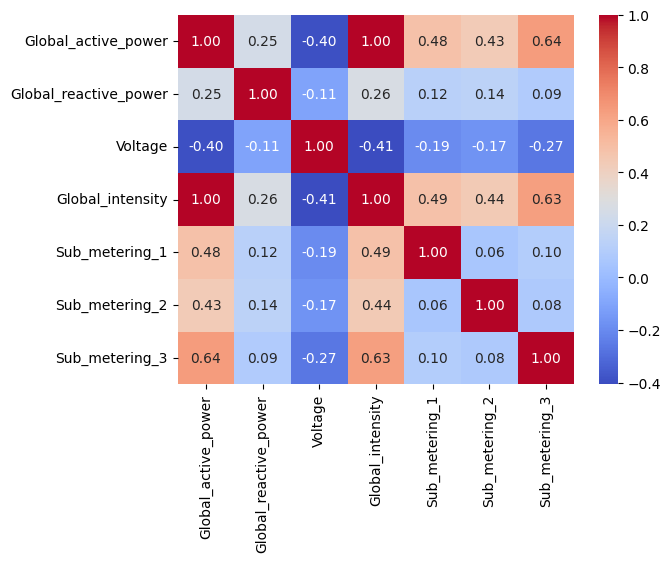

In [4]:
#Matriz de correlación
matriz_correlacion = df_limpio.corr()
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f")

Como se observa en el mapa de calor anterior, *Global_intensity* y *Global_active_power* tiene una correlación de 1, lo que nos indica redundacia entre dichas variables. Por ello, se opta por eliminar alguna de ellas, con esto en mente, decidimos eliminar *Global_intesity*, esta eliminación se justifica en la naturaleza de nuestro dateset y como se menciona en la página de donde se obtuvieron los datos, se menciona que *Global_intesity* es medida en Amperes mientras que *Global_active_power*en KiloWatts y *Sub_metering_1*, *Sub_metering_2*, *Sub_metering_3* en Watts-hora, por ello es más comodo trabajar con unidades similares. 

Dicho lo anterior, decidimos definir un umbral de $|r| > 0.7$ ya que nuestros demás datos poseen correlaciones debiles y moderadas. Esto nos permite que las demás variables las conservemeos y eliminemos unicamente *Global_intesity* por que lo mencionado en el primer párrafo. 


In [5]:
def dimensionalidad(df_limpio):
    df_limpio = df_limpio.drop(columns='Global_intensity')
    return df_limpio

In [6]:
df_limpio = dimensionalidad(df_limpio)

In [7]:
df_limpio.head()

,Global_active_power,Global_reactive_power,Voltage,Sub_metering_1,Sub_metering_2,Sub_metering_3
Date-time,,,,,,
2006-12-16 17:24:00,2.969445,2.618328,-1.850903,-0.181412,-0.049982,1.254491
2006-12-16 17:25:00,4.056249,2.778443,-2.224618,-0.181412,-0.049982,1.135667
2006-12-16 17:26:00,4.069549,3.329949,-2.329629,-0.181412,0.122830,1.254491
2006-12-16 17:27:00,4.082849,3.365531,-2.190644,-0.181412,-0.049982,1.254491
2006-12-16 17:28:00,2.446943,3.596807,-1.591465,-0.181412,-0.049982,1.254491
